Please use the AMD3090 PC, and ctrl+shift+P connect to WSL server, and using the (lab) enviroment to run this notebook

(Linux auto-sklearn required)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import numpy as np
import autosklearn as askl

from sklearn.linear_model import LinearRegression

In [2]:
pd.set_option('mode.chained_assignment',None) # supress SettingWithCopyWarning

# data loader

In [3]:
broccoli_3d_traits = pd.read_csv('./out/v230407/broccoli_traits.csv')
broccoli_3d_traits.head()

,id,crown_height(m),center.x(m),center.y(m),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2),centroid.x(m),centroid.y(m),long_axis(m),short_axis(m),orientation(degree),crown_3dconvex_volume(cm3),crown_3dconcave_volume(cm3),crown_3dconcave_alpha,crown_roundness,head_height(m),head_3dconcave_volume(cm3),head_3dconcave_alpha
0,1-1,0.061894,0.016133,0.024035,0.077561,0.080290,51.255486,55.777778,0.014071,0.021634,0.086431,0.083233,-107.199173,186.508067,12.668349,0.015,0.738451,0.146767,1.348625,0.02
1,1-11,0.086620,0.003600,0.028051,0.103729,0.107361,86.727958,92.111111,0.000738,0.033835,0.112777,0.105936,-155.841362,454.256819,10.974741,0.025,0.755419,0.157807,12.649370,0.02
2,1-12,0.067599,-0.001300,0.042465,0.089962,0.092735,67.192994,70.777778,-0.001372,0.036533,0.096714,0.094844,-79.718065,292.259786,0.760588,0.015,0.830367,0.156621,12.200190,0.02
3,1-13,0.078768,-0.002323,0.036847,0.108976,0.105372,91.288985,97.444444,0.002538,0.041451,0.115577,0.109427,-70.754398,427.798788,17.207737,0.020,0.814435,0.160057,39.196050,0.02
4,1-15,0.089891,-0.002458,0.031097,0.120156,0.117466,115.119180,120.777778,-0.001671,0.031418,0.128480,0.121926,-144.428779,601.386847,35.102462,0.020,0.784161,0.172799,1.950164,0.02


In [4]:
broccoli_field = pd.read_csv('./model2field_id.csv')
broccoli_field.head()

,Date,Model_ID,Field_ID,0,45,90,135
0,20220317,3-1,8574,6.00,6.46,6.39,6.66
1,20220317,3-2,8575,5.23,5.14,4.54,4.53
2,20220317,3-3,8576,4.36,4.53,4.54,4.94
3,20220317,3-4,8577,4.67,5.02,5.26,5.33
4,20220317,3-5,8578,5.62,5.70,5.32,5.88


In [5]:
broccoli_2d_traits = pd.read_excel('./out/props_all_2022.xlsx')
broccoli_2d_traits.head()

,date,label,area,convex_area,eccentricity,equivalent_diameter,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
0,20220321_0,275,2195,2301,0.662845,52.865497,61.468791,46.025174,55.977211,48.827068,183.923882,0.815395,368061.303157,3.956057e+06,28.569196,"[[368061.2815551026, 3956057.0713307424], [368..."
1,20220321_0,274,2512,2655,0.589631,56.554202,63.261803,51.094847,61.040001,52.439999,203.237590,0.764225,368061.039693,3.956057e+06,29.892332,"[[368061.0091929504, 3956057.388480319], [3680..."
2,20220321_0,141,2640,2708,0.486063,57.977171,62.220264,54.375771,62.156914,52.682552,197.438600,0.851039,368060.651307,3.956057e+06,30.560149,"[[368060.6217213799, 3956056.8345038854], [368..."
3,20220321_0,3,1625,1783,0.570272,45.486418,50.724595,41.668026,52.485325,38.600506,169.852814,0.707812,368059.888442,3.956057e+06,25.026932,"[[368059.87077905197, 3956057.177263872], [368..."
4,20220321_0,276,2979,3121,0.390530,61.587179,64.470901,59.351282,62.162289,61.676651,214.066017,0.816930,368061.327088,3.956057e+06,32.678574,"[[368061.2979172566, 3956056.8109018467], [368..."


# data preprocessing

## the 3d data part

In [6]:
broccoli_field['max_length'] = broccoli_field[['0', '45', '90', '135']].max(axis=1)
broccoli_field['min_length'] = broccoli_field[['0', '45', '90', '135']].min(axis=1)

In [7]:
broccoli_field.head()

,Date,Model_ID,Field_ID,0,45,90,135,max_length,min_length
0,20220317,3-1,8574,6.00,6.46,6.39,6.66,6.66,6.00
1,20220317,3-2,8575,5.23,5.14,4.54,4.53,5.23,4.53
2,20220317,3-3,8576,4.36,4.53,4.54,4.94,4.94,4.36
3,20220317,3-4,8577,4.67,5.02,5.26,5.33,5.33,4.67
4,20220317,3-5,8578,5.62,5.70,5.32,5.88,5.88,5.32


In [8]:
broccoli_3d_merge = pd.merge(broccoli_field, broccoli_3d_traits, left_on='Model_ID', right_on='id')
broccoli_3d_merge.head()

,Date,Model_ID,Field_ID,0,45,90,135,max_length,min_length,id,...,long_axis(m),short_axis(m),orientation(degree),crown_3dconvex_volume(cm3),crown_3dconcave_volume(cm3),crown_3dconcave_alpha,crown_roundness,head_height(m),head_3dconcave_volume(cm3),head_3dconcave_alpha
0,20220317,3-1,8574,6.00,6.46,6.39,6.66,6.66,6.00,3-1,...,0.073558,0.062972,-65.296804,90.544264,31.423250,0.010,0.798339,0.142084,42.108040,0.020
1,20220317,3-2,8575,5.23,5.14,4.54,4.53,5.23,4.53,3-2,...,0.059003,0.051484,-176.139473,50.526204,25.778741,0.015,0.930713,0.149868,19.931228,0.025
2,20220317,3-3,8576,4.36,4.53,4.54,4.94,4.94,4.36,3-3,...,0.052651,0.049139,-80.964335,39.632416,14.129421,0.010,0.908292,0.147616,127.465372,0.020
3,20220317,3-4,8577,4.67,5.02,5.26,5.33,5.33,4.67,3-4,...,0.060120,0.053417,-78.029467,50.215150,18.277578,0.010,0.889342,0.146556,50.012442,0.020
4,20220317,3-5,8578,5.62,5.70,5.32,5.88,5.88,5.32,3-5,...,0.063628,0.059194,-2.246206,73.213668,32.829862,0.010,0.920256,0.156164,84.052978,0.025


In [9]:
broccoli_3d_merge.columns

Index(['Date', 'Model_ID', 'Field_ID', '0', '45', '90', '135', 'max_length',
       'min_length', 'id', 'crown_height(m)', 'center.x(m)', 'center.y(m)',
       'min_rect_width(m)', 'min_rect_length(m)', 'crown_2dconvex_area(cm2)',
       'projected_leaf_area(cm2)', 'centroid.x(m)', 'centroid.y(m)',
       'long_axis(m)', 'short_axis(m)', 'orientation(degree)',
       'crown_3dconvex_volume(cm3)', 'crown_3dconcave_volume(cm3)',
       'crown_3dconcave_alpha', 'crown_roundness', 'head_height(m)',
       'head_3dconcave_volume(cm3)', 'head_3dconcave_alpha'],
      dtype='object')

In [10]:
broccoli_3d_merge_train = broccoli_3d_merge[
    ['Date', 'Field_ID', 'Model_ID',
     'long_axis(m)', 'short_axis(m)', 'crown_roundness', 'orientation(degree)',
     'min_rect_width(m)', 'min_rect_length(m)', 
     'crown_2dconvex_area(cm2)', 'projected_leaf_area(cm2)',
     'head_height(m)', 'crown_height(m)', 
     'crown_3dconvex_volume(cm3)', 'crown_3dconcave_volume(cm3)', 'head_3dconcave_volume(cm3)']
]
broccoli_3d_merge_train.head()

,Date,Field_ID,Model_ID,long_axis(m),short_axis(m),crown_roundness,orientation(degree),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2),head_height(m),crown_height(m),crown_3dconvex_volume(cm3),crown_3dconcave_volume(cm3),head_3dconcave_volume(cm3)
0,20220317,8574,3-1,0.073558,0.062972,0.798339,-65.296804,0.063708,0.061781,31.835893,35.111111,0.142084,0.050574,90.544264,31.423250,42.108040
1,20220317,8575,3-2,0.059003,0.051484,0.930713,-176.139473,0.045497,0.052653,19.398061,23.666667,0.149868,0.040657,50.526204,25.778741,19.931228
2,20220317,8576,3-3,0.052651,0.049139,0.908292,-80.964335,0.048661,0.045269,17.632555,20.111111,0.147616,0.039791,39.632416,14.129421,127.465372
3,20220317,8577,3-4,0.060120,0.053417,0.889342,-78.029467,0.047834,0.053833,20.411755,25.000000,0.146556,0.038978,50.215150,18.277578,50.012442
4,20220317,8578,3-5,0.063628,0.059194,0.920256,-2.246206,0.054661,0.059125,26.335788,29.333333,0.156164,0.047445,73.213668,32.829862,84.052978


In [11]:
broccoli_3d_merge_train.to_excel('out/autoskl_model_db.xlsx', index=False)

## the 2D data part

In [12]:
pd.unique(broccoli_2d_traits.date)

array(['20220321_0', '20220325_0', '20220329_0', '20220331_0',
       '20220405_0'], dtype=object)

In [13]:
date_replace_key = {
    '20220321_0': 20220321, 
    '20220325_0': 20220325, 
    '20220329_0': 20220329, 
    '20220331_0': 20220331,
    '20220405_0': 20220405
}

In [14]:
broccoli_2d_traits = broccoli_2d_traits.replace({"date": date_replace_key})
broccoli_2d_traits.head()

,date,label,area,convex_area,eccentricity,equivalent_diameter,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
0,20220321,275,2195,2301,0.662845,52.865497,61.468791,46.025174,55.977211,48.827068,183.923882,0.815395,368061.303157,3.956057e+06,28.569196,"[[368061.2815551026, 3956057.0713307424], [368..."
1,20220321,274,2512,2655,0.589631,56.554202,63.261803,51.094847,61.040001,52.439999,203.237590,0.764225,368061.039693,3.956057e+06,29.892332,"[[368061.0091929504, 3956057.388480319], [3680..."
2,20220321,141,2640,2708,0.486063,57.977171,62.220264,54.375771,62.156914,52.682552,197.438600,0.851039,368060.651307,3.956057e+06,30.560149,"[[368060.6217213799, 3956056.8345038854], [368..."
3,20220321,3,1625,1783,0.570272,45.486418,50.724595,41.668026,52.485325,38.600506,169.852814,0.707812,368059.888442,3.956057e+06,25.026932,"[[368059.87077905197, 3956057.177263872], [368..."
4,20220321,276,2979,3121,0.390530,61.587179,64.470901,59.351282,62.162289,61.676651,214.066017,0.816930,368061.327088,3.956057e+06,32.678574,"[[368061.2979172566, 3956056.8109018467], [368..."


In [15]:
bro_3d_key = broccoli_3d_merge_train[['Date','Field_ID']]
bro_3d_key.head()

,Date,Field_ID
0,20220317,8574
1,20220317,8575
2,20220317,8576
3,20220317,8577
4,20220317,8578


In [16]:
merged_db = pd.merge(broccoli_3d_merge_train, broccoli_2d_traits, left_on=['Date', 'Field_ID'], right_on=['date', 'label'])
merged_db.head()

,Date,Field_ID,Model_ID,long_axis(m),short_axis(m),crown_roundness,orientation(degree),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),...,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
0,20220321,1245,1-1,0.086431,0.083233,0.738451,-107.199173,0.077561,0.080290,51.255486,...,61.558329,50.172129,57.693344,51.838436,191.137085,0.829998,368067.403989,3.956051e+06,29.590226,"[[368067.37477707077, 3956051.240633216], [368..."
1,20220321,1246,1-2,0.079354,0.076798,0.830665,-33.594187,0.074119,0.071904,43.599239,...,54.847846,48.866144,52.650005,48.824356,179.923882,0.809742,368067.537986,3.956051e+06,27.186651,"[[368067.51684707473, 3956050.880208683], [368..."
2,20220321,1247,1-3,0.075681,0.072879,0.859747,-59.415376,0.070155,0.068206,37.334887,...,51.522202,50.799673,53.745083,48.994579,172.509668,0.860150,368067.634970,3.956051e+06,26.730172,"[[368067.61745483143, 3956050.51356814], [3680..."
3,20220321,1248,1-4,0.098476,0.089518,0.784639,-92.630809,0.091717,0.088844,63.632262,...,65.689160,62.124487,63.946243,59.350517,220.651804,0.822578,368067.743483,3.956050e+06,33.613080,"[[368067.7195102528, 3956050.1843657517], [368..."
4,20220321,1249,1-5,0.093837,0.087869,0.847306,-169.938421,0.082471,0.089089,58.139292,...,62.803942,57.898223,62.194767,57.975765,213.001046,0.781357,368067.818881,3.956050e+06,32.265269,"[[368067.7875027895, 3956049.7950738384], [368..."


In [17]:
merged_db.columns

Index(['Date', 'Field_ID', 'Model_ID', 'long_axis(m)', 'short_axis(m)',
       'crown_roundness', 'orientation(degree)', 'min_rect_width(m)',
       'min_rect_length(m)', 'crown_2dconvex_area(cm2)',
       'projected_leaf_area(cm2)', 'head_height(m)', 'crown_height(m)',
       'crown_3dconvex_volume(cm3)', 'crown_3dconcave_volume(cm3)',
       'head_3dconcave_volume(cm3)', 'date', 'label', 'area', 'convex_area',
       'eccentricity', 'equivalent_diameter', 'major_axis_length',
       'minor_axis_length', 'min_area_rect_max', 'min_area_rect_min',
       'perimeter', 'circularity', 'circular_x', 'circular_y', 'circular_r',
       'polygon'],
      dtype='object')

In [18]:
X = merged_db[[
    'major_axis_length', 'minor_axis_length', # 'circularity',
    'min_area_rect_min', 'min_area_rect_max',
    'area', 'convex_area',
]]
X.head()

,major_axis_length,minor_axis_length,min_area_rect_min,min_area_rect_max,area,convex_area
0,61.558329,50.172129,51.838436,57.693344,2413,2518
1,54.847846,48.866144,48.824356,52.650005,2086,2199
2,51.522202,50.799673,48.994579,53.745083,2037,2096
3,65.689160,62.124487,59.350517,63.946243,3187,3272
4,62.803942,57.898223,57.975765,62.194767,2821,3013


In [19]:
X.major_axis_length /= 1000
X.minor_axis_length /= 1000
X.min_area_rect_max /= 1000
X.min_area_rect_min /= 1000
X.area /= 100
X.convex_area /= 100

X.head()

,major_axis_length,minor_axis_length,min_area_rect_min,min_area_rect_max,area,convex_area
0,0.061558,0.050172,0.051838,0.057693,24.13,25.18
1,0.054848,0.048866,0.048824,0.052650,20.86,21.99
2,0.051522,0.050800,0.048995,0.053745,20.37,20.96
3,0.065689,0.062124,0.059351,0.063946,31.87,32.72
4,0.062804,0.057898,0.057976,0.062195,28.21,30.13


In [20]:
Y = merged_db[[
     'long_axis(m)', 'short_axis(m)', 'crown_roundness',
     'min_rect_width(m)', 'min_rect_length(m)', 
     'crown_2dconvex_area(cm2)', 'projected_leaf_area(cm2)',
     'head_height(m)', 'crown_height(m)', 
     'crown_3dconvex_volume(cm3)', 'crown_3dconcave_volume(cm3)', 'head_3dconcave_volume(cm3)']]
Y.head()

,long_axis(m),short_axis(m),crown_roundness,min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2),head_height(m),crown_height(m),crown_3dconvex_volume(cm3),crown_3dconcave_volume(cm3),head_3dconcave_volume(cm3)
0,0.086431,0.083233,0.738451,0.077561,0.080290,51.255486,55.777778,0.146767,0.061894,186.508067,12.668349,1.348625
1,0.079354,0.076798,0.830665,0.074119,0.071904,43.599239,47.222222,0.168830,0.048860,139.816980,14.477226,5.525235
2,0.075681,0.072879,0.859747,0.070155,0.068206,37.334887,42.888889,0.162643,0.046383,109.211521,5.154304,1.024164
3,0.098476,0.089518,0.784639,0.091717,0.088844,63.632262,68.111111,0.184527,0.056775,242.457441,24.708370,5.911781
4,0.093837,0.087869,0.847306,0.082471,0.089089,58.139292,64.000000,0.174870,0.049455,195.340140,1.158646,0.074548


In [21]:
Y = merged_db[[
     'long_axis(m)', 'short_axis(m)', # 'crown_roundness',
     'min_rect_width(m)', 'min_rect_length(m)', 
     'crown_2dconvex_area(cm2)', 'projected_leaf_area(cm2)']]

Y.head()

,long_axis(m),short_axis(m),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2)
0,0.086431,0.083233,0.077561,0.080290,51.255486,55.777778
1,0.079354,0.076798,0.074119,0.071904,43.599239,47.222222
2,0.075681,0.072879,0.070155,0.068206,37.334887,42.888889
3,0.098476,0.089518,0.091717,0.088844,63.632262,68.111111
4,0.093837,0.087869,0.082471,0.089089,58.139292,64.000000


In [22]:
plot_ratio = np.array([1, 1, 1, 1, 0.001, 0.001])

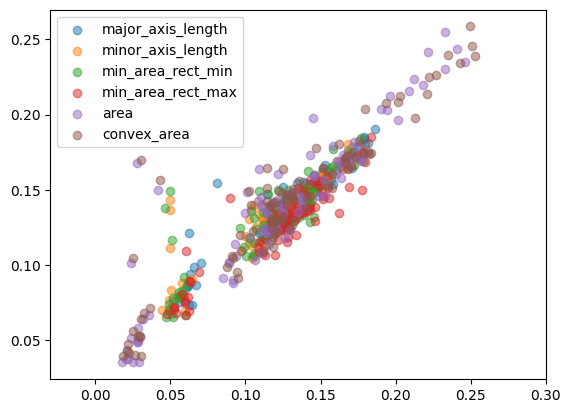

In [23]:
for i in range(X.shape[1]):
    plt.scatter(X.iloc[:, i]*plot_ratio[i], Y.iloc[:, i]*plot_ratio[i], label=X.columns[i], alpha=0.5)

plt.axis('equal')
plt.legend()
plt.show()

remove the noises?

In [24]:
from sklearn.preprocessing import normalize

In [25]:
np.set_printoptions(suppress=True)

In [26]:
npx = X.to_numpy()
npy = Y.to_numpy()

diff_norm = np.abs(normalize(npx - npy, axis=0))
diff_norm.shape

(93, 6)

In [27]:
diff = diff_norm.sum(axis=1)
diff.shape

(93,)

(array([57., 19., 10.,  4.,  0.,  0.,  2.,  0.,  0.,  1.]),
 array([0.06393368, 0.35191361, 0.63989355, 0.92787348, 1.21585342,
        1.50383335, 1.79181329, 2.07979322, 2.36777315, 2.65575309,
        2.94373302]),
 <BarContainer object of 10 artists>)

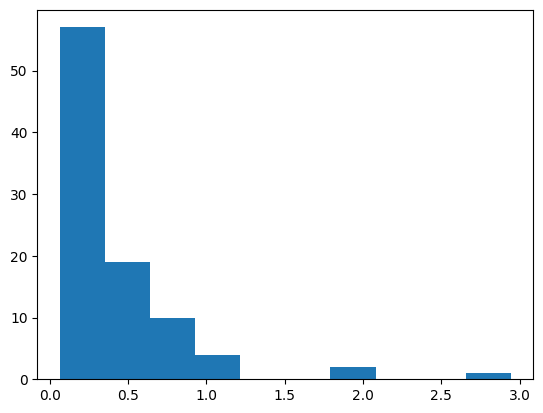

In [28]:
plt.hist(diff)

In [29]:
noise_idx = diff>1.5
noise_idx

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,  True, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

In [30]:
noise_idx_int = np.where(diff>1.5)[0]
noise_idx_int

array([13, 38, 59])

In [31]:
noise_db = merged_db.iloc[noise_idx_int, :]
noise_db

,Date,Field_ID,Model_ID,long_axis(m),short_axis(m),crown_roundness,orientation(degree),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),...,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
13,20220329,9474,6-15,0.121160,0.111054,0.784014,-45.025728,0.116597,0.109151,100.941923,...,62.158401,49.894589,60.466805,51.012798,190.580736,0.830008,368114.261861,3.956043e+06,29.789494,"[[368114.2413515892, 3956043.4012894346], [368..."
38,20220331,5277,5-21,0.146938,0.136706,0.810783,-8.941818,0.137902,0.135252,149.565262,...,114.094154,49.765004,123.198395,46.489491,304.592929,0.561835,368092.322371,3.956041e+06,62.660674,"[[368092.26621530723, 3956040.6078304616], [36..."
59,20220331,5333,8-26,0.154413,0.143240,0.758643,-29.183165,0.149319,0.144723,167.812976,...,80.784937,49.768266,89.674759,49.753712,244.929978,0.578143,368096.735078,3.956021e+06,45.074296,"[[368096.69550908665, 3956021.044634557], [368..."


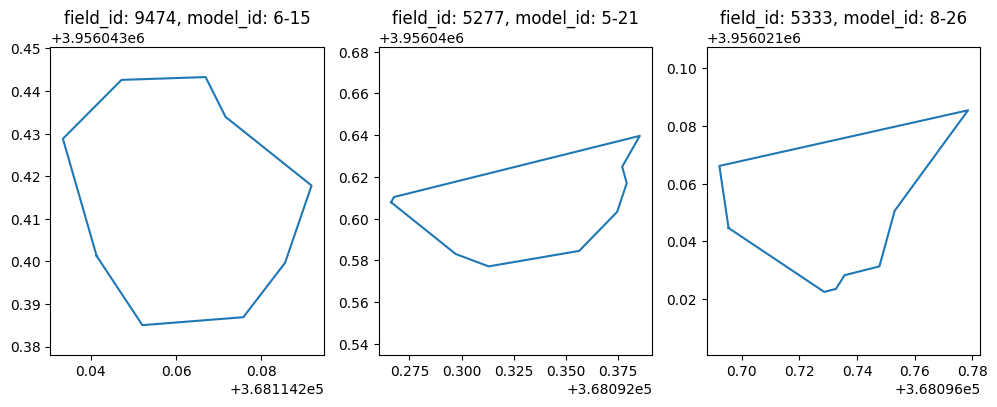

In [32]:
fig, ax = plt.subplots(1,3, figsize=(12,4))
for i, idx in enumerate(noise_idx_int):
    aaa = np.asarray(eval(noise_db.polygon[idx]))
    ax[i].plot(*aaa.T)

    ax[i].set_title(f'field_id: {noise_db.Field_ID[idx]}, model_id: {noise_db.Model_ID[idx]}')
    ax[i].axis('equal')

plt.show()

In [33]:
from matplotlib.pyplot import cm

In [34]:
col_rename_dict = {
    'major_axis_length': 'length of\nmajor axis\n(m)', 
    'minor_axis_length': 'length of\nminor axis\n(m)', 
    'min_area_rect_min': 'width of\nmin. area\nrect. (m)',
    'min_area_rect_max': 'length of\nmin. area\nrect. (m)', 
    'area': 'area\n($10^3 \cdot cm^2$)', 
    'convex_area': 'convex area\n($10^3 \cdot cm^2$)',
}

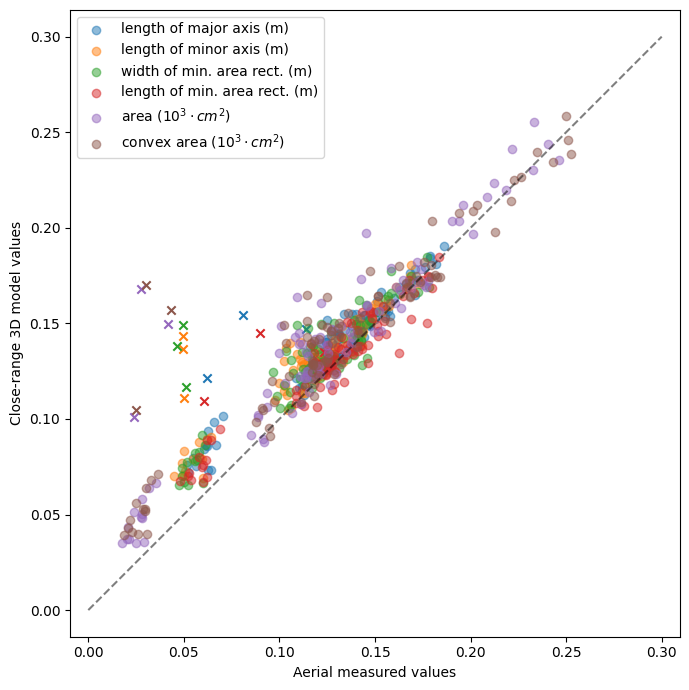

In [35]:
for i in range(X.shape[1]):
    plt.scatter(X.iloc[~noise_idx, i]*plot_ratio[i], 
                Y.iloc[~noise_idx, i]*plot_ratio[i], 
                label=col_rename_dict[X.columns[i]].replace('\n', ' '), 
                alpha=0.5, color=cm.tab10(i),
                rasterized=True)
    plt.scatter(X.iloc[noise_idx, i]*plot_ratio[i], 
                Y.iloc[noise_idx, i]*plot_ratio[i], 
                marker='x', color=cm.tab10(i),
                rasterized=True)

plt.plot([0, 0.3], [0, 0.3], 'k--', alpha=0.5)
plt.gca().set_xlim(0, 0.3)
plt.gca().set_ylim(0, 0.3)
plt.gcf().set_size_inches((7, 7))
plt.gca().set_xlabel('Aerial measured values')
plt.gca().set_ylabel('Close-range 3D model values')
plt.axis('equal')
plt.legend()
plt.tight_layout()
plt.savefig('out/train_denoise.pdf')
plt.show()

# auto-sklearn

In [36]:
from sklearn.datasets import make_regression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

from autosklearn.regression import AutoSklearnRegressor

In [37]:
random_state = 1
train_size = 0.8

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X.to_numpy()[~noise_idx, :], Y.to_numpy()[~noise_idx, :], random_state=random_state, train_size=train_size)

In [40]:
X_train.shape

(72, 6)

In [41]:
y_test.shape

(18, 6)

In [39]:
automl = AutoSklearnRegressor(
    time_left_for_this_task=120,
    per_run_time_limit=30,
    memory_limit=1024*8,
    tmp_folder="/tmp/autosklearn_multioutput_regression_example_tmp",
)

In [40]:
automl.fit(X_train, y_train)

[WARNING] [2023-05-24 15:46:59,835:Client-AutoMLSMBO(1)::c708c261-f9fe-11ed-84f2-00155d2bcb00] Could not find meta-data directory /home/crest/miniconda3/envs/lab/lib/python3.9/site-packages/autosklearn/metalearning/files/r2_multioutput.regression_dense


AutoSklearnRegressor(ensemble_class=<class 'autosklearn.ensembles.ensemble_selection.EnsembleSelection'>,
                     memory_limit=8192, per_run_time_limit=30,
                     time_left_for_this_task=120,
                     tmp_folder='/tmp/autosklearn_multioutput_regression_example_tmp')

In [44]:
import pickle

with open(f'out/autoskl_{askl.__version__}_model_{random_state}.pkl', 'wb') as handle:
    pickle.dump(automl, handle,  protocol=pickle.HIGHEST_PROTOCOL)

the older version
```python
>>> print(automl.leaderboard())

          rank  ensemble_weight                 type      cost  duration
model_id                                                                
60           1             0.38  k_nearest_neighbors  0.065348  0.274729
24           2             0.10  k_nearest_neighbors  0.071966  0.258442
65           3             0.02  k_nearest_neighbors  0.079608  0.272072
29           4             0.14  k_nearest_neighbors  0.092576  0.259468
54           5             0.20  k_nearest_neighbors  0.092576  0.295085
28           6             0.14        decision_tree  0.111839  0.267479
18           7             0.02        random_forest  0.152083  0.485200
```

In [41]:
#The newer version
print(automl.leaderboard())

          rank  ensemble_weight                 type      cost  duration
model_id                                                                
72           1             0.22        random_forest  0.074515  0.571865
55           2             0.08        random_forest  0.074982  0.992214
2            3             0.02        random_forest  0.075378  0.554909
73           4             0.28        random_forest  0.077250  2.037851
69           5             0.24        random_forest  0.091262  0.615694
67           6             0.06  k_nearest_neighbors  0.117884  0.259571
20           7             0.10  k_nearest_neighbors  0.238692  0.265826


In [42]:
predictions = automl.predict(X_test)

print(f'total_r2 = {r2_score(y_test, predictions)}')
for i in range(y_test.shape[1]):
    print(f"R2 score of {Y.columns[i]}: ", r2_score(y_test[:,i], predictions[:,i]))

total_r2 = 0.9006532660304417
R2 score of long_axis(m):  0.9275440341036945
R2 score of short_axis(m):  0.922347813401427
R2 score of min_rect_width(m):  0.8851565852324089
R2 score of min_rect_length(m):  0.8446708648573431
R2 score of crown_2dconvex_area(cm2):  0.9064310862937751
R2 score of projected_leaf_area(cm2):  0.9177692122940013


In [47]:
predictions.shape

(18, 6)

In [48]:
# compare to linear regression
lr_model = LinearRegression().fit(X_train, y_train)
lr_predict = lr_model.predict(X_test)

print(f'total_r2 = {r2_score(lr_predict, y_test)}')
for i in range(y_test.shape[1]):
    print(f"R2 score of {Y.columns[i]}: ", r2_score(y_test[:,i], lr_predict[:,i]))

total_r2 = 0.8976056192594006
R2 score of long_axis(m):  0.9238093792828143
R2 score of short_axis(m):  0.8975201179558905
R2 score of min_rect_width(m):  0.9050917326129299
R2 score of min_rect_length(m):  0.8217896959507691
R2 score of crown_2dconvex_area(cm2):  0.8980219671327169
R2 score of projected_leaf_area(cm2):  0.9048963178442249


In [43]:
valid_plot_ratio = np.array([100, 100, 100, 100, 1, 1])

labels = [
    'length of major axis (cm)',
    'length of minor axis (cm)',
    'width of min. area rect. (cm)',
    'length of min. area rect. (cm)', 
    'area ($cm^2$)',
    'convex area ($cm^2$)'
]

In [56]:
from regression import linear

y=0.791x+3.591  R^2=0.95
RMSE = 0.582734858434027
-----------------
y=1.015x+-0.083  R^2=0.93
RMSE = 0.6609595096281661
-----------------
y=0.765x+4.183  R^2=0.89
RMSE = 0.7093548089229209
-----------------
y=0.95x+0.799  R^2=0.93
RMSE = 0.5791122202828242
-----------------
y=0.806x+3.731  R^2=0.84
RMSE = 0.9719622835132097
-----------------
y=1.011x+0.178  R^2=0.9
RMSE = 0.7718310416507642
-----------------
y=0.72x+3.797  R^2=0.88
RMSE = 0.802783149310266
-----------------
y=0.892x+1.378  R^2=0.86
RMSE = 0.8663332893185615
-----------------
y=0.851x+35.146  R^2=0.9
RMSE = 13.646997168823797
-----------------
y=0.924x+13.382  R^2=0.92
RMSE = 12.56279504359495
-----------------
y=0.814x+39.121  R^2=0.91
RMSE = 12.85222210310658
-----------------
y=0.931x+12.164  R^2=0.93
RMSE = 11.732410711138145
-----------------


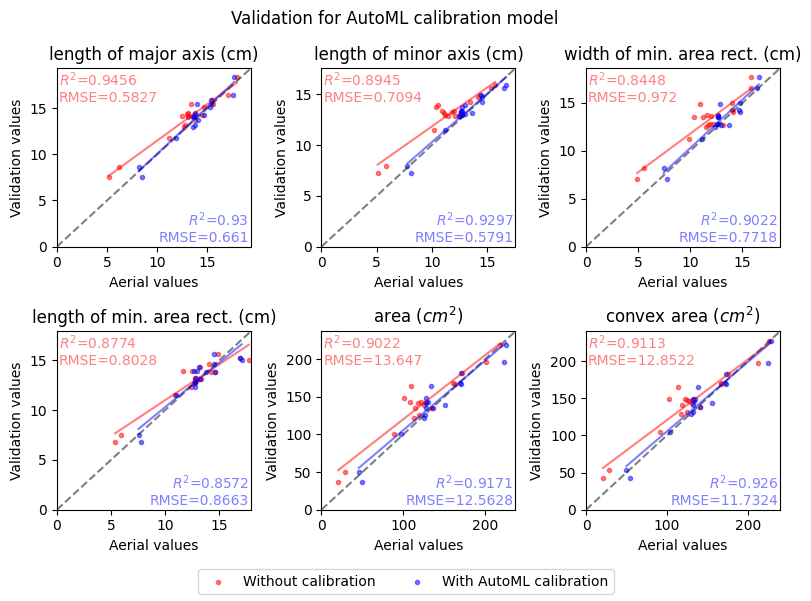

In [71]:
fig, ax = plt.subplots(2,3, figsize=(8, 6))

for i in range(y_test.shape[1]):
    yy = y_test[:, i] * valid_plot_ratio[i]
    xx = predictions[:, i]  * valid_plot_ratio[i]
    xx_prime = X_test[:, i] * valid_plot_ratio[i]

    amax = max(xx.max(), yy.max()) * 1.05

    ax[i // 3, i % 3].plot([0,amax], [0, amax], 'k--', alpha=0.5)
    xplb = ax[i // 3, i % 3].scatter(xx_prime, yy, marker='.', alpha=0.5, color='r')
    xlb = ax[i // 3, i % 3].scatter(xx, yy, marker='.', alpha=0.5, color='b')

    ax[i // 3, i % 3].set_title(labels[i])

    ax[i // 3, i % 3].set_xlim(0, amax)
    ax[i // 3, i % 3].set_ylim(0, amax)

    ax[i // 3, i % 3].set_xlabel('Aerial values')
    ax[i // 3, i % 3].set_ylabel('Validation values')

    x_points, y_points, y_predict, t, r2_p, rmse_p = linear(xx_prime, yy)
    ax[i // 3, i % 3].plot(x_points, y_points, '-', color='r', alpha=0.5)
    
    x_points, y_points, y_predict, t, r2, rmse = linear(xx, yy)
    ax[i // 3, i % 3].plot(x_points, y_points, '-', color='b', alpha=0.5)

    # r2_prime = r2_score(xx_prime, predictions[:,i])
    # r2 = r2_score(y_test[:,i], predictions[:,i])

    ax[i // 3, i % 3].text(
        amax*0.01,amax*0.99, 
        f'$R^2$={round(r2_p, 4)}\nRMSE={round(rmse_p, 4)}', 
        va='top', color='r', alpha=0.5)
    ax[i // 3, i % 3].text(
        amax*0.99,amax*0.01, 
        f'$R^2$={round(r2, 4)}\nRMSE={round(rmse, 4)}', 
        va='bottom', ha='right',color='b', alpha=0.5)

# ax[1,3].axis('off')
plt.suptitle(f"Validation for AutoML calibration model")
fig.legend([xplb, xlb], ['Without calibration', 'With AutoML calibration'], ncol=2, loc='lower center')
plt.tight_layout(rect=[0,0.05,1,1])
plt.savefig('out/validation4automl.pdf')
plt.show()

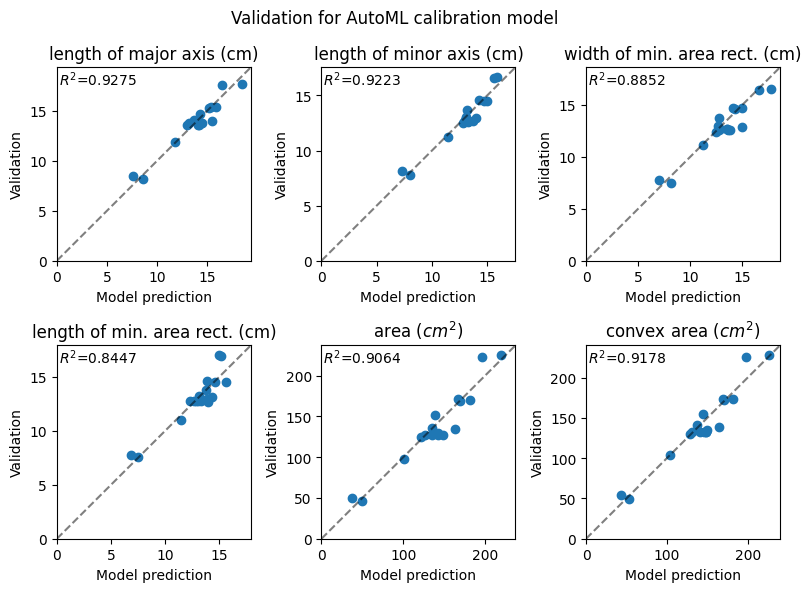

In [56]:
fig, ax = plt.subplots(2,3, figsize=(8, 6))

for i in range(y_test.shape[1]):
    xx = y_test[:, i] * valid_plot_ratio[i]
    yy = predictions[:, i]  * valid_plot_ratio[i]
    amax = max(xx.max(), yy.max()) * 1.05

    ax[i // 3, i % 3].plot([0,amax], [0, amax], 'k--', alpha=0.5)
    ax[i // 3, i % 3].scatter(xx, yy)
    ax[i // 3, i % 3].set_title(labels[i])

    ax[i // 3, i % 3].set_xlim(0, amax)
    ax[i // 3, i % 3].set_ylim(0, amax)

    ax[i // 3, i % 3].set_xlabel('Model prediction')
    ax[i // 3, i % 3].set_ylabel('Validation')

    r2 = r2_score(y_test[:,i], predictions[:,i])

    ax[i // 3, i % 3].text(amax*0.01,amax*0.99, f'$R^2$={round(r2, 4)}', va='top')

# ax[1,3].axis('off')
plt.suptitle(f"Validation for AutoML calibration model")
plt.tight_layout()
plt.savefig('out/validation4automl.pdf')
plt.show()

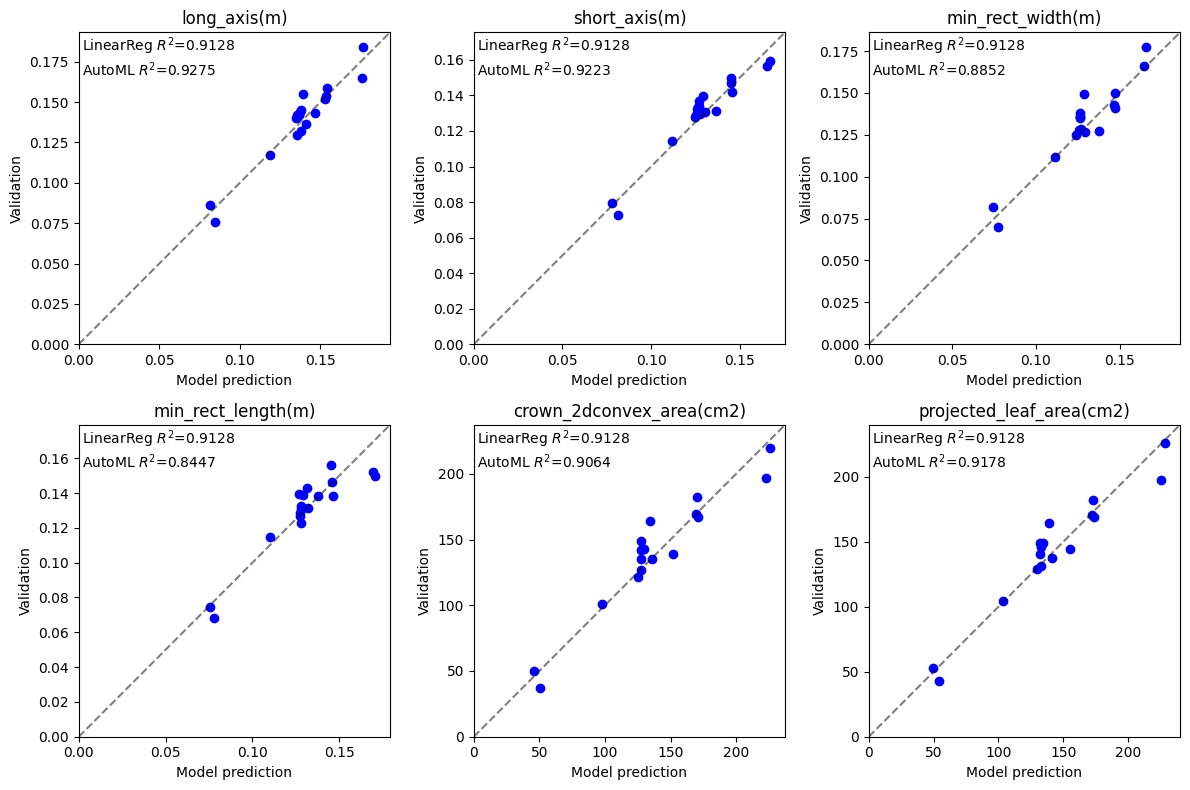

In [72]:
fig, ax = plt.subplots(2,3, figsize=(12, 8))

for i in range(y_test.shape[1]):
    amax = max(predictions[:, i].max(), y_test[:, i].max()) * 1.05

    ax[i // 3, i % 3].plot([0,amax], [0, amax], 'k--', alpha=0.5)
    ax[i // 3, i % 3].scatter(predictions[:, i], y_test[:, i], color='b')
    ax[i // 3, i % 3].set_title(Y.columns[i])

    ax[i // 3, i % 3].set_xlim(0, amax)
    ax[i // 3, i % 3].set_ylim(0, amax)

    ax[i // 3, i % 3].set_xlabel('Model prediction')
    ax[i // 3, i % 3].set_ylabel('Validation')

    r2 = r2_score(y_test[:,i], predictions[:,i])

    ax[i // 3, i % 3].text(amax*0.01,amax*0.99, f'LinearReg $R^2$={round(lr_r2, 4)}\nAutoML $R^2$={round(r2, 4)}', va='top')

# ax[1,3].axis('off')

plt.tight_layout()
plt.show()